In [ ]:
import requests, os

base = "https://divvy-tripdata.s3.amazonaws.com/"
months = ["202409","202410","202411","202412",
          "202501","202502","202503","202504",
          "202505","202506","202507","202508","202509"]

os.makedirs("divvy_data", exist_ok=True)
for m in months:
    print(f"Downloading {m}...", end=" ")
    r = requests.get(f"{base}{m}-divvy-tripdata.zip")
    open(f"divvy_data/{m}.zip", "wb").write(r.content)
    print("OK")

print("\nSelesai! Cek isinya:")
print(os.listdir("divvy_data"))



Selesai! Cek isinya:
['202508.zip', '202507.zip', '202410.zip', '202503.zip', '202502.zip', '202505.zip', '202504.zip', '202506.zip', '202509.zip', '202409.zip', '202412.zip', '202501.zip', '202411.zip']


In [ ]:
import zipfile, glob
import pandas as pd

# 1. Extract semua zip
for z in sorted(glob.glob("divvy_data/*.zip")):
    with zipfile.ZipFile(z, 'r') as zip_ref:
        zip_ref.extractall("divvy_data/")
print("Extract selesai!")

# 2. Load semua CSV, gabung jadi satu
dfs = []
for f in sorted(glob.glob("divvy_data/*.csv")):
    d = pd.read_csv(f)
    dfs.append(d)
    print(f"{f.split('/')[-1]}: {d.shape}")

df = pd.concat(dfs, ignore_index=True)
print(f"\nTOTAL: {df.shape}")
print(df.head(3))


Extract selesai!
202409-divvy-tripdata.csv: (821276, 13)
202410-divvy-tripdata.csv: (616281, 13)
202411-divvy-tripdata.csv: (335075, 13)
202412-divvy-tripdata.csv: (178372, 13)
202501-divvy-tripdata.csv: (138689, 13)
202502-divvy-tripdata.csv: (151880, 13)
202503-divvy-tripdata.csv: (298155, 13)
202504-divvy-tripdata.csv: (371341, 13)
202505-divvy-tripdata.csv: (502456, 13)
202506-divvy-tripdata.csv: (678904, 13)
202507-divvy-tripdata.csv: (763432, 13)
202508-divvy-tripdata.csv: (790177, 13)
202509-divvy-tripdata.csv: (714759, 13)

TOTAL: (6360797, 13)
            ride_id  rideable_type               started_at  \
0  31D38723D5A8665A  electric_bike  2024-09-26 15:30:58.150   
1  67CB39987F4E895B  electric_bike  2024-09-26 15:31:32.529   
2  DA61204FD26EC681  electric_bike  2024-09-26 15:00:33.012   

                  ended_at start_station_name start_station_id  \
0  2024-09-26 15:30:59.437                NaN              NaN   
1  2024-09-26 15:53:13.501                NaN           

In [ ]:
print("=== Null per kolom ===")
print(df.isnull().sum())
print(f"\nBaris duplikat: {df.duplicated().sum()}")
print(f"\nTipe rider: {df['member_casual'].unique()}")
print(df['member_casual'].value_counts())
print(f"\nTipe data:")
print(df.dtypes)


=== Null per kolom ===
ride_id                     0
rideable_type               0
started_at                  0
ended_at                    0
start_station_name    1318179
start_station_id      1318179
end_station_name      1368785
end_station_id        1368785
start_lat                   0
start_lng                   0
end_lat                  6195
end_lng                  6195
member_casual               0
dtype: int64

Baris duplikat: 0

Tipe rider: ['member' 'casual']
member_casual
member    4017835
casual    2342962
Name: count, dtype: int64

Tipe data:
ride_id                object
rideable_type          object
started_at             object
ended_at               object
start_station_name     object
start_station_id       object
end_station_name       object
end_station_id         object
start_lat             float64
start_lng             float64
end_lat               float64
end_lng               float64
member_casual          object
dtype: object


In [ ]:
# Konversi ke datetime
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

# ride_length dalam menit
df['ride_length'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

print(df['ride_length'].describe())
print(f"\nride_length <= 0 (trip mustahil): {(df['ride_length'] <= 0).sum()}")
print(f"ride_length > 1440 (lebih dari 24 jam): {(df['ride_length'] > 1440).sum()}")


count    6.360797e+06
mean     1.607578e+01
std      5.447972e+01
min     -5.602170e+01
25%      5.424117e+00
50%      9.466467e+00
75%      1.663422e+01
max      1.574900e+03
Name: ride_length, dtype: float64

ride_length <= 0 (trip mustahil): 43
ride_length > 1440 (lebih dari 24 jam): 6316


In [ ]:
# Buang trip mustahil
df_clean = df[(df['ride_length'] > 0) & (df['ride_length'] <= 1440)].copy()
print(f"Sebelum: {len(df):,} → Sesudah: {len(df_clean):,}")
print(f"Dibuang: {len(df) - len(df_clean):,} baris")

# Tambah kolom hari
df_clean['day_of_week'] = df_clean['started_at'].dt.day_name()
print("\nDistribusi hari:")
print(df_clean['day_of_week'].value_counts())


Sebelum: 6,360,797 → Sesudah: 6,354,438
Dibuang: 6,359 baris

Distribusi hari:
day_of_week
Saturday     974785
Friday       943156
Thursday     927026
Tuesday      910719
Wednesday    879524
Monday       869551
Sunday       849677
Name: count, dtype: int64


In [ ]:
print("=== Rata-rata durasi trip (menit) ===")
print(df_clean.groupby('member_casual')['ride_length'].mean())

print("\n=== Median durasi trip (menit) ===")
print(df_clean.groupby('member_casual')['ride_length'].median())

print("\n=== Jumlah trip ===")
print(df_clean['member_casual'].value_counts())


=== Rata-rata durasi trip (menit) ===
member_casual
casual    19.331804
member    11.849505
Name: ride_length, dtype: float64

=== Median durasi trip (menit) ===
member_casual
casual    11.434467
member     8.573817
Name: ride_length, dtype: float64

=== Jumlah trip ===
member_casual
member    4016935
casual    2337503
Name: count, dtype: int64


In [ ]:
# Jumlah trip per tipe rider per hari
pivot = df_clean.groupby(['member_casual', 'day_of_week']).size().unstack()

order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = pivot[order]

print("=== % trip per hari (per tipe rider) ===")
print((pivot.div(pivot.sum(axis=1), axis=0) * 100).round(1))


=== % trip per hari (per tipe rider) ===
day_of_week    Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
member_casual                                                                
casual           12.1     11.4       11.2      12.6    15.4      20.1    17.2
member           14.6     16.0       15.4      15.7    14.5      12.6    11.2


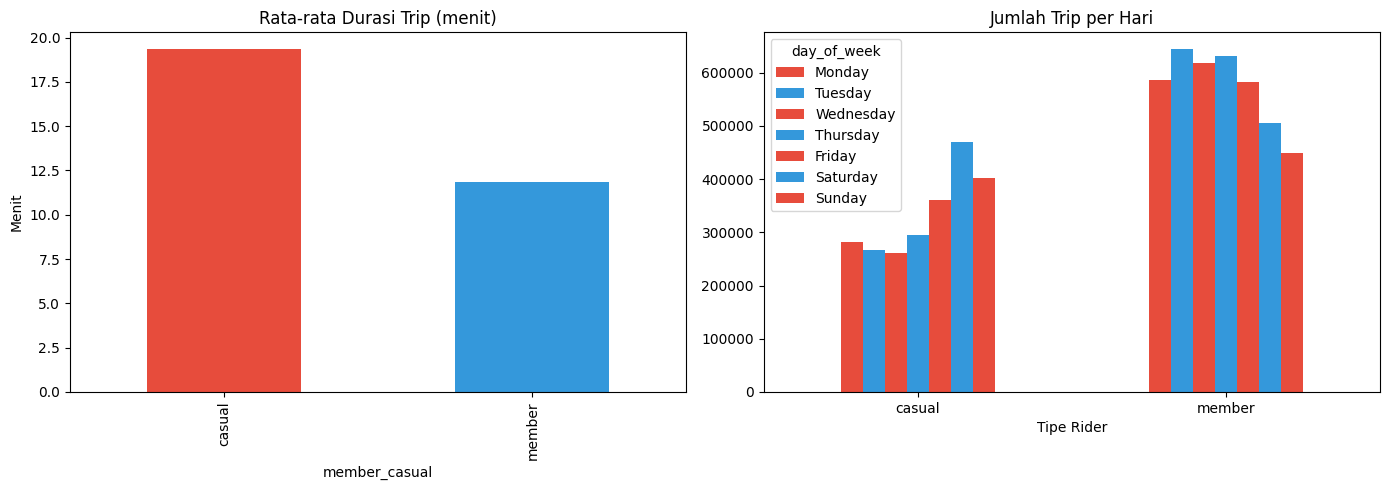

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: rata-rata durasi per tipe rider
df_clean.groupby('member_casual')['ride_length'].mean().plot(
    kind='bar', ax=axes[0], color=['#e74c3c', '#3498db'])
axes[0].set_title('Rata-rata Durasi Trip (menit)')
axes[0].set_ylabel('Menit')

# Chart 2: jumlah trip per hari per tipe rider
pivot.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#3498db'])
axes[1].set_title('Jumlah Trip per Hari')
axes[1].set_xlabel('Tipe Rider')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


In [ ]:
# Simpen chart sebagai gambar (buat README GitHub)
fig.savefig('divvy_analysis.png', dpi=150, bbox_inches='tight')
print("Chart tersimpan!")


Chart tersimpan!
